In [1]:
from typing import Literal, Tuple
from anndata import AnnData
from tqdm.auto import tqdm
from pycirclize import Circos
from bokeh.palettes import all_palettes

import re
import os
import glob
import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.colorbar as colorbar

/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial'] # Ensure 'Arial' is in the sans-serif list
# fontsize
FONTSIZE = 6

In [3]:
fig_path = "./final_figures"
os.makedirs(fig_path, exist_ok=True)

In [4]:
def _check_robustness_fractions(
    df_pivot, 
    threshold_qval=0.1, # adjusted p value
    threshold_valid=0.5, # fraction of results required to even consider this condition. I.e. if the test only ran for one set of thresholds, then it is not very robust.
    threshold_below_alpha=0.75, # fraction of results that need to be significant
):
    n_total = np.prod(df_pivot.shape)
    n_valid = n_total - df_pivot.isna().sum().sum()
    n_below_alpha = (df_pivot < threshold_qval).sum().sum() # number of results below pval threshold, i.e., number of significant results
    frac_valid_results = (n_valid / n_total)
    frac_pval_below_alpha = (n_below_alpha / n_valid) # fraction of significant results relative to valid results
    is_robust = (frac_pval_below_alpha > threshold_below_alpha) & (frac_valid_results > threshold_valid)
    return frac_valid_results, frac_pval_below_alpha, is_robust


def check_robustness(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_VALID = 0.5,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)

    df2 = df.copy()
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                df_pivot_nes = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="NES")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                    df_combined2 = pd.concat([df2, df_pivot_nes])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged2 = df_combined2.combine_first(df_pivot_nes)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_merged2 = df_merged2.loc[~df_merged2.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                df_pivot_nes = df_merged2.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(
                    df_pivot,
                    threshold_qval=THRESHOLD_QVAL,
                    threshold_valid=THRESHOLD_VALID,
                    threshold_below_alpha=THRESHOLD_BELOW_ALPHA
                )
                
                if is_robust:
                    # print(df_pivot_nes.max().max(), df_pivot_nes.min().min())
                    if (df_pivot_nes.max().max() > 0) and (df_pivot_nes.min().min() < 0):
                        sns.heatmap(df_pivot, cmap="Reds_r", center=0, vmin=0, vmax=0.1, square=True)
                        plt.show()
                        sns.heatmap(df_pivot_nes, cmap="RdBu_r", center=0, square=True)
                        plt.show()
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results

    

def check_robustness_old(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_VALID = 0.5,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(
                    df_pivot,
                    threshold_qval=THRESHOLD_QVAL,
                    threshold_valid=THRESHOLD_VALID,
                    threshold_below_alpha=THRESHOLD_BELOW_ALPHA
                )
                
                if is_robust:
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results


def get_robust_significant_results(
    results,
    alphas = [0.1, 0.05, 0.01],
):

    results_robust = []
    for alpha in alphas:
        results_robust.append(check_robustness(results, THRESHOLD_QVAL=alpha, THRESHOLD_VALID=THRESHOLD_VALID, THRESHOLD_BELOW_ALPHA=THRESHOLD_BELOW_ALPHA))
    results_robust = pd.concat(results_robust)
    results_robust = results_robust.groupby(["contrast", "celltype_combo", "cytokine"])["qval_threshold"].min().to_frame().reset_index()
    
    results_mean = results.fillna(0).groupby(["contrast", "celltype_combo", "cytokine"])["NES"].mean().to_frame().reset_index()
    results_pivot = results_mean.pivot(
        index="cytokine",
        columns="celltype_combo",
        values="NES",
    )
    df_annot = results_pivot.copy()
    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)
        df_annot[:] = ""
    for cytokine in df_annot.index:
        for celltype in df_annot.columns:
            qval = results_robust.loc[(results_robust.cytokine == cytokine) & (results_robust.celltype_combo == celltype)].qval_threshold
            if len(qval) != 0:
                qval = qval.values[0]
                if qval == 0.1:
                    df_annot.loc[cytokine, celltype] = "*"
                if qval == 0.05:
                    df_annot.loc[cytokine, celltype] = "**"
                if qval == 0.01:
                    df_annot.loc[cytokine, celltype] = "***"

    return results_pivot, df_annot, results_robust


def format_cytokine_names(x):
    if isinstance(x, (list, np.ndarray, pd.Index)):
        return [format_cytokine_names(_x) for _x in x]
    text = x.get_text() if hasattr(x, 'get_text') else x
    text = text.replace("beta", r"$\beta$")
    text = text.replace("alpha", r"$\alpha$")
    text = text.replace("gamma", r"$\gamma$")
    text = text.replace("lambda", r"$\lambda$")
    text = text.replace("omega", r"$\omega$")
    return text


def format_celltype_names(x):
    if isinstance(x, (list, np.ndarray, pd.Index)):
        return [format_celltype_names(_x) for _x in x]
    text = x.get_text() if hasattr(x, 'get_text') else x
    # text = text.replace("CD4-positive, alpha-beta T cell", r"CD4, $\alpha$-$\beta$ T")
    text = text.replace("CD4-positive, alpha-beta T cell", r"CD4 T")
    # text = text.replace("CD8-positive, alpha-beta T cell", r"CD8, $\alpha$-$\beta$ T")
    text = text.replace("CD8-positive, alpha-beta T cell", r"CD8 T")
    text = text.replace("conventional dendritic cell", "cDC")
    text = text.replace("natural killer cell", "NK")
    if not text.startswith("NK"):
        text = text.split("(")[0]
    else:
        #text = text.replace("CD56-bright_NK", "CD56hi")
        #text = text.replace("CD56-dim_NK", "CD56low")
        #text = text.replace("NK_CD56hi", "CD56hi")
        text = text.replace("NK_CD56hi", "hi")
        #text = text.replace("NK_CD56low", "CD56low")
        text = text.replace("NK_CD56low", "low")
    if text.startswith("non-classical monocyte"):
        text =  "nc. Mono."
    elif text.startswith("classical monocyte"):
        text =  "c. Mono."
    return text

In [5]:
paths = glob.glob("./results_robustness_final_DEGs/results_lupus_robustness_*.csv")
all_results = []
for path in paths:
    threshold_expression = float(path.split("_")[-1].split(".csv")[0])
    results = pd.read_csv(path, index_col=0)
    results.loc[:, "threshold_expression"] = threshold_expression
    all_results.append(results)
all_results = pd.concat(all_results, axis=0, ignore_index=True)

valid_contrasts = ['flare_vs_na', 'flare_vs_treated']
all_results = all_results.loc[(all_results.contrast.isin(valid_contrasts)) & (all_results.threshold_expression >= 0.05)]

In [6]:
all_results.percent_duplicate_ranking_stats.max()

np.float64(0.0423549343498517)

In [7]:
# flare vs healthy
results_fvh = all_results.loc[all_results.contrast == 'flare_vs_na']
results_fvt = all_results.loc[all_results.contrast == 'flare_vs_treated']

In [8]:
THRESHOLD_VALID = 1/3
THRESHOLD_BELOW_ALPHA = 2/3

In [9]:
CELLTYPE_ORDER = [
    'B cell (B_cell)',
    'CD4-positive, alpha-beta T cell (CD4_T_cell)',
    'CD8-positive, alpha-beta T cell (CD8_T_cell)', 
    'natural killer cell (NK_CD56hi)',
    'natural killer cell (NK_CD56low)',
    'classical monocyte (CD14_Mono)',   
    'non-classical monocyte (CD16_Mono)',
    'conventional dendritic cell (cDC)',
]

selected_cytokines = [
    "IFN-beta",
    "IFN-gamma",
    "IL-15",
    "IL-4", 
    # "IL-1-beta",
    "IL-32-beta",
    # "Leptin",
    "M-CSF",
]

### flare vs healthy

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  2.13it/s]


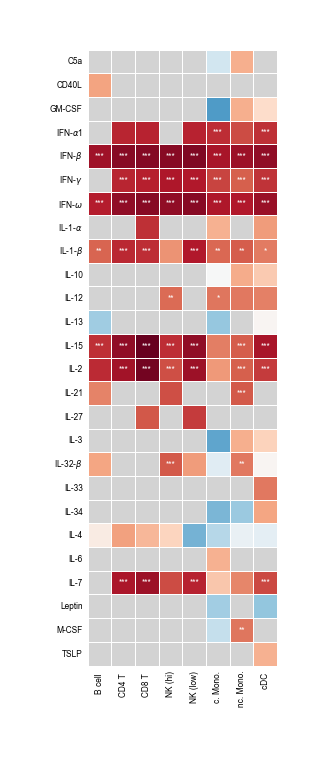

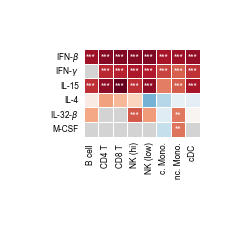

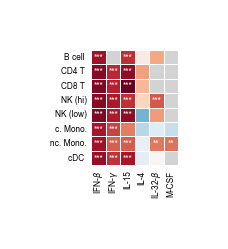

In [10]:
results_pivot_fvh, df_annot_fvh, results_robust_fvh = get_robust_significant_results(results_fvh)

results_pivot_fvh = results_pivot_fvh.T.loc[CELLTYPE_ORDER].T

df_annot_fvh = df_annot_fvh.T.loc[CELLTYPE_ORDER].T

fig, ax = plt.subplots(1,1,figsize=(8, 8))
sns.heatmap(
    results_pivot_fvh,
    square=True,
    annot=df_annot_fvh,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_fvh.columns)
plt.xticks(0.5+np.arange(results_pivot_fvh.shape[1]), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

cytokine_labels = format_cytokine_names(results_pivot_fvh.index)
plt.yticks(0.5+np.arange(results_pivot_fvh.shape[0]), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")

plt.show()

results_pivot_fvh_selected = results_pivot_fvh.loc[selected_cytokines]
df_annot_fvh_selected = df_annot_fvh.loc[selected_cytokines]

fig, ax = plt.subplots(1,1,figsize=(1.5, 1.5))
sns.heatmap(
    results_pivot_fvh_selected,
    square=True,
    annot=df_annot_fvh_selected,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_fvh_selected.columns)
plt.xticks(0.5+np.arange(results_pivot_fvh_selected.shape[1]), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

cytokine_labels = format_cytokine_names(results_pivot_fvh_selected.index)
plt.yticks(0.5+np.arange(results_pivot_fvh_selected.shape[0]), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")

if True:
    plt.savefig(
        os.path.join(fig_path, "enichment_heatmap_lupus_cytokines_selected_flare_vs_healthy.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        # transparent=True,
    )

plt.show()

results_pivot_fvh_selected = results_pivot_fvh_selected.T
df_annot_fvh_selected = df_annot_fvh_selected.T

fig, ax = plt.subplots(1,1,figsize=(1.5, 1.5))
sns.heatmap(
    results_pivot_fvh_selected,
    square=True,
    annot=df_annot_fvh_selected,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_fvh_selected.index)
plt.yticks(0.5+np.arange(len(celltype_labels)), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")

cytokine_labels = format_cytokine_names(results_pivot_fvh_selected.columns)
plt.xticks(0.5+np.arange(len(cytokine_labels)), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

if True:
    plt.savefig(
        os.path.join(fig_path, "enichment_heatmap_lupus_cytokines_selected_flare_vs_healthy_T.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        #transparent=True,
    )

plt.show()

### Flare vs treated

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  2.21it/s]


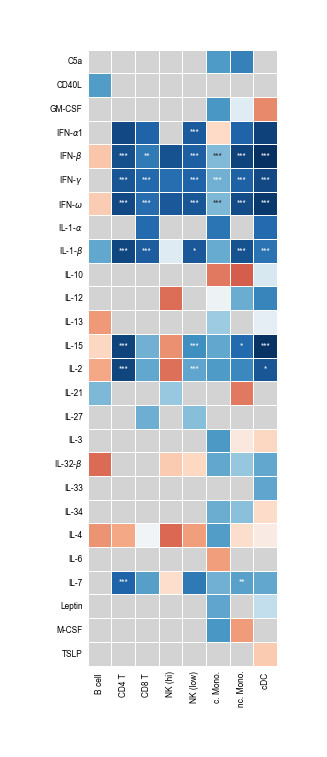

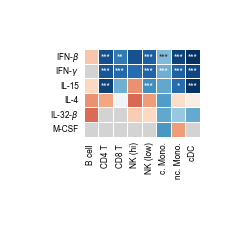

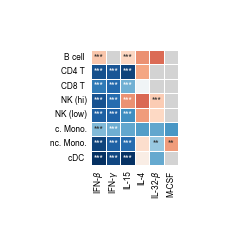

In [11]:
results_pivot_fvt, df_annot_fvt, results_robust_fvt = get_robust_significant_results(results_fvt)

results_pivot_fvt = results_pivot_fvt.T.loc[CELLTYPE_ORDER].T

fig, ax = plt.subplots(1,1,figsize=(8, 8))
sns.heatmap(
    results_pivot_fvt,
    square=True,
    annot=df_annot_fvt,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_fvt.columns)
plt.xticks(0.5+np.arange(results_pivot_fvt.shape[1]), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

cytokine_labels = format_cytokine_names(results_pivot_fvt.index)
plt.yticks(0.5+np.arange(results_pivot_fvt.shape[0]), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")
plt.show()

results_pivot_fvt_selected = results_pivot_fvt.loc[selected_cytokines]
df_annot_fvt_selected = df_annot_fvt.loc[selected_cytokines]

fig, ax = plt.subplots(1,1,figsize=(1.5, 1.5))
sns.heatmap(
    results_pivot_fvt_selected,
    square=True,
    annot=df_annot_fvt_selected,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_fvt_selected.columns)
plt.xticks(0.5+np.arange(results_pivot_fvt_selected.shape[1]), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

cytokine_labels = format_cytokine_names(results_pivot_fvt_selected.index)
plt.yticks(0.5+np.arange(results_pivot_fvt_selected.shape[0]), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")

if True:
    plt.savefig(
        os.path.join(fig_path, "enichment_heatmap_lupus_cytokines_selected_flare_vs_treated.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        # transparent=True,
    )

plt.show()



results_pivot_fvt_selected = results_pivot_fvt_selected.T
df_annot_fvt_selected = df_annot_fvt_selected.T

fig, ax = plt.subplots(1,1,figsize=(1.5, 1.5))
sns.heatmap(
    results_pivot_fvt_selected,
    square=True,
    annot=df_annot_fvh_selected,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_fvt_selected.index)
plt.yticks(0.5+np.arange(len(celltype_labels)), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")

cytokine_labels = format_cytokine_names(results_pivot_fvt_selected.columns)
plt.xticks(0.5+np.arange(len(cytokine_labels)), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

if True:
    plt.savefig(
        os.path.join(fig_path, "enichment_heatmap_lupus_cytokines_selected_flare_vs_treated_T.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        # transparent=True,
    )

plt.show()